# Velora Brewing - Data Cleaning and Preprocessing
**Week 5 deliverable: Reusable preprocessing pipeline**

**What is data cleaning?** Fixing or flagging anything in the data that would give wrong answers later: blanks, repeats, wrong types, odd values, and values that contradict each other. **Preprocessing** then turns the clean data into numbers a machine-learning model can use (encoding and scaling).

The pipeline code lives in `src/` so any table can use it:

| File | Job |
|---|---|
| `src/cleaning.py` | 4 generic cleaners + the Velora business fixes |
| `src/preprocess.py` | encoding, scaling, date-based train/test split |
| `src/test_cleaning.py` | proves the cleaners work on deliberately messy data |
| `src/run_cleaning.py` | runs everything and writes `reports/cleaning_report.md` |

This notebook runs the pipeline and shows the results. Run the cells in order with **Shift+Enter**.

In [1]:
import os, sys
from pathlib import Path

PROJECT = None   # Only if the next lines fail: put your project path here, e.g. r"C:\Users\you\velora-brewing-analytics"
start = Path(PROJECT) if PROJECT else Path.cwd()
for folder in [start, *start.parents]:
    if (folder / "src" / "load_data.py").exists():
        os.chdir(folder); break
else:
    raise FileNotFoundError("Project folder not found. Set PROJECT above to your project folder path.")
sys.path.append("src")
print("Working folder:", Path.cwd())

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from load_data import load_data_tables
from cleaning import clean_all, convert_types, remove_duplicates, handle_missing, flag_outliers, CleanLog

sns.set_theme(style="whitegrid"); plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 12})
BLUE, ORANGE = "#2E6F95", "#E07A5F"
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 80)

Working folder: /home/claude/velora-brewing-analytics


## 1. Run the pipeline on the real data
`clean_all(raw)` is the whole pipeline in one call. It returns the cleaned tables, a **log** of every action, an **outlier table**, and a list of **checks**.

In [2]:
raw = load_data_tables()
clean, log, outliers, checks = clean_all(raw)

print(f"{len(raw)} raw tables in  ->  {len(clean)} tables out (4 are new analysis-ready tables)")
print("Rows removed:", sum(len(raw[n]) - len(clean[n]) for n in raw))
print("\nPost-cleaning checks:")
for text, ok in checks:
    print(f"  [{'OK  ' if ok else 'FAIL'}] {text}")

17 raw tables in  ->  21 tables out (4 are new analysis-ready tables)
Rows removed: 0

Post-cleaning checks:
  [OK  ] every primary key is unique
  [OK  ] net_sales = qty x price x (1 - discount), within 1%
  [OK  ] production_loss = planned - actual
  [OK  ] lead_time_days = actual delivery - order date
  [OK  ] every sales line has an order, product and customer
  [OK  ] every batch has a QC result
  [OK  ] no order is dated before its customer's rebuilt first_order_date
  [OK  ] season matches the calendar month in every Demand_History row


**Finding.** The raw file is structurally tidy: **no rows were removed**, there are no duplicates, no blank primary keys and no text-stored numbers. The only generic change was `Product_Master.launch_date`, stored as text and converted to a date. So the real cleaning work is **fixing contradictions** (next section), and the pipeline's generic cleaners are proven on messy data in Section 4.

### The log: every action the pipeline took

In [3]:
display(log)

,table,step,detail,count
0,Product_Master,type conversion,launch_date: converted to date,13
1,Customers,business rule,first_order_date rebuilt from Sales_Orders (stated one kept as *_stated),598
2,Customers,business rule,customers with no orders (first_order_date left missing),1
3,Sales_Orders,business rule,is_cancelled flag added (revenue excludes these),765
4,Demand_History,business rule,season rebuilt from month (stated one kept as *_stated),473
5,Demand_History,business rule,rows after 2026-10-31 flagged is_forecast_period,26
6,Suppliers,business rule,on_time_rate_calc added from deliveries (stated rate kept as *_stated),20
7,Suppliers,business rule,"main_category renamed main_category_stated (unreliable, see known issue 3)",20
8,sales_lines,business rule,"order lines joined with order, product and customer info",11278
9,batches_qc,business rule,"batches joined with their QC test, product target and is_review flag",465


## 2. The business fixes: before and after
These are the data issues we documented in Steps 2 and 5. Each one is now fixed in code, and the original value is kept in a `*_stated` column so nothing is lost.

In [4]:
from run_cleaning import before_after
display(before_after(raw, clean))

print("\nCustomers: stated vs rebuilt first_order_date (first 5)")
c = clean["Customers"]
display(c[["customer_id", "first_order_date_stated", "first_order_date"]].head())

print("Demand_History: stated season vs season rebuilt from the month (first 6 January-to-March rows)")
d = clean["demand"]
display(d[d["month_no"].isin([1, 2, 3])][["month", "product_id", "season_stated", "season"]].head(6))

print("Suppliers: stated vs calculated on-time rate (first 5)")
display((clean["Suppliers"][["supplier_name", "on_time_rate_stated", "on_time_rate_calc"]].head()).round(2))

,Check,Before,After
0,Orders placed before the customer's first_order_date,52.0%,0.0%
1,Demand_History rows whose season matches the month,24.2%,100.0%
2,Average supplier on-time rate,90.0% (stated),42.7% (calculated)
3,Demand_History rows that are after the data cutoff (Nov-Dec 2026),mixed in with real history,"26 flagged, excluded from training"
4,Cancelled orders in revenue,included unless filtered by hand,765 flagged; net_sales_counted_eur = 0 for them



Customers: stated vs rebuilt first_order_date (first 5)


,customer_id,first_order_date_stated,first_order_date
0,CUS0001,2023-08-23,2024-01-24
1,CUS0002,2026-03-31,2023-07-16
2,CUS0003,2026-10-19,2023-06-28
3,CUS0004,2024-02-11,2023-01-25
4,CUS0005,2026-07-08,2024-08-07


Demand_History: stated season vs season rebuilt from the month (first 6 January-to-March rows)


,month,product_id,season_stated,season
0,2023-01-01,VLR001,Spring,Winter
1,2023-01-01,VLR002,Autumn,Winter
2,2023-01-01,VLR003,Summer,Winter
3,2023-01-01,VLR004,Summer,Winter
4,2023-01-01,VLR005,Autumn,Winter
5,2023-01-01,VLR006,Summer,Winter


Suppliers: stated vs calculated on-time rate (first 5)


,supplier_name,on_time_rate_stated,on_time_rate_calc
0,Danube Malt Co,0.87,0.46
1,Alpine Hops GmbH,0.95,0.35
2,Adria Packaging,0.84,0.36
3,GreenYeast Labs,0.85,0.40
4,Baltic Glassworks,0.96,0.33


**Finding.** After the fixes, **0%** of orders precede their customer's first order (before: 52%), **100%** of seasons match the calendar (before: 24%), and the supplier on-time rate comes from real deliveries (43%, not the stated 90%). 26 Demand_History rows for Nov-Dec 2026 are flagged `is_forecast_period` so models do not train on months that have not happened.

## 3. Outliers: judge values inside their own group
**Rule (IQR):** a value is flagged if it is more than 1.5 x IQR outside the middle 50% of the data. **Important:** the same rule on *all rows together* gives wrong answers, because different materials and expense types live on very different scales.

,column,judged all together,judged inside its group,group
0,Unit cost,123,0,material_id
1,Purchase value,114,0,material_id
2,Monthly expense,83,0,expense_category
3,Units per order line,0,0,sales_channel


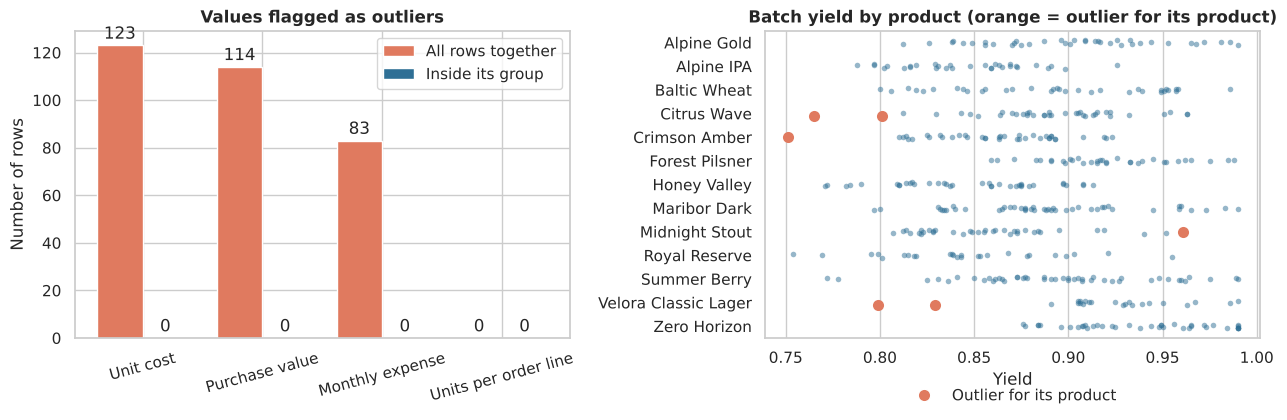


All outlier checks (only columns with at least one flag):


,table,column,judged_within,flagged,share_pct,rows
4,batches_qc,yield_rate,product_id,6,1.29,465
7,batches_qc,defect_units,all rows,1,0.22,465
13,procurement,lead_time_days,supplier_id,16,1.33,1200
17,demand,units_sold,product_id,2,0.32,624
18,Marketing_Campaigns,spend_eur,channel,1,1.67,60
19,Marketing_Campaigns,clicks,channel,4,6.67,60


In [5]:
tests = [("procurement", "unit_cost_eur", "material_id", "Unit cost"),
         ("procurement", "purchase_value_eur", "material_id", "Purchase value"),
         ("Monthly_Expenses", "amount_eur", "expense_category", "Monthly expense"),
         ("sales_lines", "quantity_units", "sales_channel", "Units per order line")]
rows = []
for table, col, grp, label in tests:
    df = clean[table]
    rows.append({"column": label, "judged all together": int(flag_outliers(df, col).sum()),
                 "judged inside its group": int(flag_outliers(df, col, grp).sum()), "group": grp})
cmp = pd.DataFrame(rows); display(cmp)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
x = np.arange(len(cmp)); w = 0.38
b1 = ax[0].bar(x - w / 2, cmp["judged all together"], w, color=ORANGE, label="All rows together")
b2 = ax[0].bar(x + w / 2, cmp["judged inside its group"], w, color=BLUE, label="Inside its group")
ax[0].bar_label(b1, padding=2); ax[0].bar_label(b2, padding=2)
ax[0].set_xticks(x); ax[0].set_xticklabels(cmp["column"], rotation=15); ax[0].legend()
ax[0].set(title="Values flagged as outliers", ylabel="Number of rows")

b = clean["batches_qc"].sort_values("product_name")
sns.stripplot(data=b[~b["yield_rate_outlier"]], x="yield_rate", y="product_name", color=BLUE, alpha=0.5, size=4, ax=ax[1])
sns.stripplot(data=b[b["yield_rate_outlier"]], x="yield_rate", y="product_name", color=ORANGE, size=8, ax=ax[1])
from matplotlib.lines import Line2D
ax[1].legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor=ORANGE, markersize=9, label="Outlier for its product")], loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
ax[1].set(title="Batch yield by product (orange = outlier for its product)", xlabel="Yield", ylabel="")
fig.tight_layout(); fig.savefig("reports/figures/fig20_outliers_grouped.png", dpi=130, bbox_inches="tight"); plt.show()

print("\nAll outlier checks (only columns with at least one flag):")
display(outliers[outliers["flagged"] > 0])

**Finding.** Judged all together, unit cost shows **123** outliers, purchase value **114** and monthly expenses **83**, but only because hops cost more than bottles and Labour costs more than Rent. Judged inside their own group, all three drop to **0**. (Units per order line has none either way, so grouping only matters where scales really differ.) The few real flags are 6 unusual yields, 16 long lead times, 4 high click counts, 2 demand values, 1 spend value and 1 defect count. All lie inside a possible range, so they are **flagged and kept**, not deleted.

## 4. Proof the cleaners work: a deliberately messy table
The real file is tidy, so we damage a copy (400 order lines): dates and amounts as text, stray spaces, wrong upper/lower case, 30 blanks, 20 duplicate rows and one absurd quantity. Then we clean it with the same functions.

In [6]:
from test_cleaning import make_dirty
base = clean["sales_lines"]
dirty = make_dirty(base)

print("BEFORE cleaning")
print(f"  rows: {len(dirty)} | blanks in quantity_units: {dirty['quantity_units'].isna().sum()} | duplicate rows: {dirty.duplicated().sum()}")
print("  order_date dtype:", dirty["order_date"].dtype, "| net_sales_eur dtype:", dirty["net_sales_eur"].dtype)
display(dirty[["order_id", "order_date", "net_sales_eur", "sales_channel", "quantity_units"]].head(4))

mlog = CleanLog()
fixed = convert_types(dirty, "demo", mlog, dayfirst=True)
fixed = remove_duplicates(fixed, "demo", mlog, key="order_line_id")
fixed = handle_missing(fixed, "demo", mlog, key="order_line_id", group="sales_channel")
fixed["qty_outlier"] = flag_outliers(fixed, "quantity_units", group="sales_channel")

print("\nAFTER cleaning")
print(f"  rows: {len(fixed)} | blanks: {fixed['quantity_units'].isna().sum()} | duplicate rows: {fixed.duplicated().sum()}")
print("  order_date dtype:", fixed["order_date"].dtype, "| net_sales_eur dtype:", fixed["net_sales_eur"].dtype)
display(fixed[["order_id", "order_date", "net_sales_eur", "sales_channel", "quantity_units"]].head(4))
print(f"  absurd quantity (900,000) flagged as outlier: {bool(fixed['qty_outlier'].iloc[5])}")
print("\nWhat the pipeline did:"); display(mlog.frame())

BEFORE cleaning
  rows: 420 | blanks in quantity_units: 32 | duplicate rows: 19
  order_date dtype: str | net_sales_eur dtype: str


,order_id,order_date,net_sales_eur,sales_channel,quantity_units
0,ord000001,08/11/2025,"EUR 1,330.55",RETAIL,1086.0
1,ord000001,08/11/2025,EUR 969.04,RETAIL,NaN
2,ord000001,08/11/2025,EUR 880.89,RETAIL,573.0
3,ord000002,13/07/2025,EUR 24.02,ONLINE,14.0



AFTER cleaning
  rows: 400 | blanks: 0 | duplicate rows: 0
  order_date dtype: datetime64[us] | net_sales_eur dtype: float64


,order_id,order_date,net_sales_eur,sales_channel,quantity_units
0,ORD000001,2025-11-08,1330.55,Retail,1086.0
1,ORD000001,2025-11-08,969.04,Retail,588.0
2,ORD000001,2025-11-08,880.89,Retail,573.0
3,ORD000002,2025-07-13,24.02,Online,14.0


  absurd quantity (900,000) flagged as outlier: True

What the pipeline did:


,table,step,detail,count
0,demo,type conversion,order_id: IDs trimmed / upper-cased,420
1,demo,type conversion,net_sales_eur: text converted to number,420
2,demo,type conversion,order_date: converted to date,420
3,demo,type conversion,sales_channel: extra spaces removed,420
4,demo,type conversion,sales_channel: inconsistent upper/lower case unified,26
5,demo,duplicates,identical rows removed,19
6,demo,duplicates,repeated order_line_id removed (first kept),1
7,demo,missing values,quantity_units: filled with group median,30


**Finding.** Every kind of damage was repaired and logged. `python src/test_cleaning.py` runs 14 automatic checks on this mess and all pass, which is why the functions can be reused on any other table. Note the `dayfirst=True` option: without it, dates like 01/02/2025 are read as 2 January, and the test shows this really happens.

## 5. Encoding and scaling for machine learning
Models need numbers on similar scales. **Encoding** turns words into 0/1 columns; **scaling** puts numbers on one scale (mean 0). **Golden rule:** learn the medians, means and categories from the **training** rows only, then apply them to the test rows, and split by **date** (train = 2023 to 2025, test = 2026).

In [7]:
from preprocess import prepare, QC_PROBLEM, DEMAND_PROBLEM

for label, prob in [("QC status (classification)", QC_PROBLEM), ("Monthly demand (regression)", DEMAND_PROBLEM)]:
    r = prepare(clean, prob)
    n_num = len(prob["numeric"])
    print(f"{label}: train {r['X_train'].shape}, test {r['X_test'].shape}")
    print(f"  numbers: {n_num} scaled | words: {len(prob['categorical'])} -> {len(r['feature_names']) - n_num} one-hot columns")
    print(f"  mean of scaled TRAIN numbers: {r['X_train'].iloc[:, :n_num].mean().abs().mean():.4f} (about 0 by design)")
    print(f"  mean of scaled TEST numbers:  {r['X_test'].iloc[:, :n_num].mean().abs().mean():.4f} (not 0: test is scaled with TRAIN values, no peeking)\n")

qc = prepare(clean, QC_PROBLEM)
print("A few of the encoded QC columns:", [c for c in qc["feature_names"] if c.startswith(("product_name", "production_line", "batch_status"))][:6])
display(qc["X_train"].iloc[:4, :6].round(2))
print("Share of Review batches in train vs test:", f"{qc['y_train'].mean():.1%} vs {qc['y_test'].mean():.1%}")

QC status (classification): train (364, 29), test (101, 29)
  numbers: 10 scaled | words: 3 -> 19 one-hot columns
  mean of scaled TRAIN numbers: 0.0000 (about 0 by design)
  mean of scaled TEST numbers:  0.1541 (not 0: test is scaled with TRAIN values, no peeking)

Monthly demand (regression): train (468, 20), test (130, 20)
  numbers: 3 scaled | words: 2 -> 17 one-hot columns
  mean of scaled TRAIN numbers: 0.0000 (about 0 by design)
  mean of scaled TEST numbers:  0.9365 (not 0: test is scaled with TRAIN values, no peeking)

A few of the encoded QC columns: ['product_name_Alpine Gold', 'product_name_Alpine IPA', 'product_name_Baltic Wheat', 'product_name_Citrus Wave', 'product_name_Crimson Amber', 'product_name_Forest Pilsner']


,planned_volume_litre,yield_rate,shift_count,temperature_c,ph_value,specific_gravity
0,-0.49,0.54,-0.36,0.83,-0.70,1.04
1,1.17,-0.61,0.52,-1.62,1.19,-0.50
2,1.38,1.31,-1.24,-0.59,-0.67,1.81
3,-1.08,0.60,-0.36,-0.32,0.71,1.32


Share of Review batches in train vs test: 30.5% vs 26.7%


**Finding.** Both modelling problems are ready: the QC problem has 465 batches split into train and test by year, and the demand problem excludes the 26 future-month rows. The scaled training numbers have mean 0 while the test numbers do not, which shows the scaler learned only from the past. The target (`is_review`) is 30.5% of train and 26.7% of test, close enough for a fair split. The demand test mean is larger because 2026 lies outside the training years, so a model using the raw `year` must extrapolate a trend; keep that in mind in Step 8.

## 6. Summary

| # | What we did | Why |
|---|---|---|
| 1 | Built 4 generic cleaners (types, duplicates, missing, outliers) | Reusable on any table; proven on messy data |
| 2 | Rebuilt `first_order_date` and `season` | Stated values contradicted the data |
| 3 | Added calculated supplier on-time rate | Stated rate was unusable |
| 4 | Flagged cancelled orders, 2026 partial year, Nov-Dec 2026 demand | Keep counts correct and avoid training on the future |
| 5 | Flagged outliers inside groups, deleted none | Group-wise rule avoids false alarms; extremes are valid |
| 6 | Encoding and scaling with a date-based split | Leakage-safe preparation for Steps 7 and 8 |

**Next (Step 7, Week 6):** statistics and feature engineering on the cleaned tables: confidence intervals, hypothesis tests, seasonality and lag features.